# 01 – Data search: small test (L02 data acquisition plan)
Smallest useful test for the Sentinel-2 main dataset: **one AOI (Ajoie), one 2 × 2 km subset, window late 2018.** It answers: does the search work, how cloudy is it, can one scene be loaded, is NDVI plausible, and do labels exist yet? Results go to `data/data_test_results.csv` and can be pasted into `data/data_inventory.md`. Details: `data/data_inventory.md` / `.csv`.

In [1]:
from pathlib import Path
import time, json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pystac_client, planetary_computer, odc.stac

ROOT = Path("..").resolve(); DATA = ROOT / "data"; DATA.mkdir(exist_ok=True)
AOI = "ajoie_ju"
AOI_BBOX = (7.02, 47.39, 7.20, 47.50)
TEST_BBOX = (7.08, 47.42, 7.105, 47.438)     # ~2 x 2 km inside the AOI
WINDOW = ("2018-08-15", "2018-09-30")
CRS, RES = "EPSG:32632", 10
result = dict(aoi=AOI, window=f"{WINDOW[0]}/{WINDOW[1]}")

## 1 · Search

In [2]:
cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                modifier=planetary_computer.sign_inplace)
t0 = time.time()
items = list(cat.search(collections=["sentinel-2-l2a"], bbox=TEST_BBOX, datetime=f"{WINDOW[0]}/{WINDOW[1]}",
                        query={"eo:cloud_cover": {"lt": 70}}).item_collection())
cc = sorted((i.properties["eo:cloud_cover"], i.datetime.date().isoformat(), i.id) for i in items)
result.update(n_scenes=len(items), search_seconds=round(time.time() - t0, 1),
              best_cloud=cc[0][0] if cc else None)
pd.DataFrame(cc, columns=["cloud_cover_%", "date", "item_id"]).head(10)

,cloud_cover_%,date,item_id
0,0.038878,2018-09-27,S2B_MSIL2A_20180927T103019_R108_T31TGN_2020100...
1,0.044917,2018-09-27,S2B_MSIL2A_20180927T103019_R108_T32TLT_2020100...
2,0.105786,2018-09-17,S2B_MSIL2A_20180917T103019_R108_T32TLT_2020100...
3,0.315749,2018-09-17,S2B_MSIL2A_20180917T103019_R108_T31TGN_2020100...
4,2.366572,2018-08-28,S2B_MSIL2A_20180828T103019_R108_T32TLT_2020110...
5,2.549865,2018-08-28,S2B_MSIL2A_20180828T103019_R108_T31TGN_2020110...
6,8.632530,2018-08-23,S2A_MSIL2A_20180823T103021_R108_T31TGN_2020101...
7,13.243346,2018-09-12,S2A_MSIL2A_20180912T103021_R108_T31TGN_2020100...
8,14.552115,2018-09-12,S2A_MSIL2A_20180912T103021_R108_T32TLT_2020100...
9,24.763783,2018-08-23,S2A_MSIL2A_20180823T103021_R108_T32TLT_2020101...


## 2 · Load the least cloudy scene (B04, B08, SCL) and compute NDVI

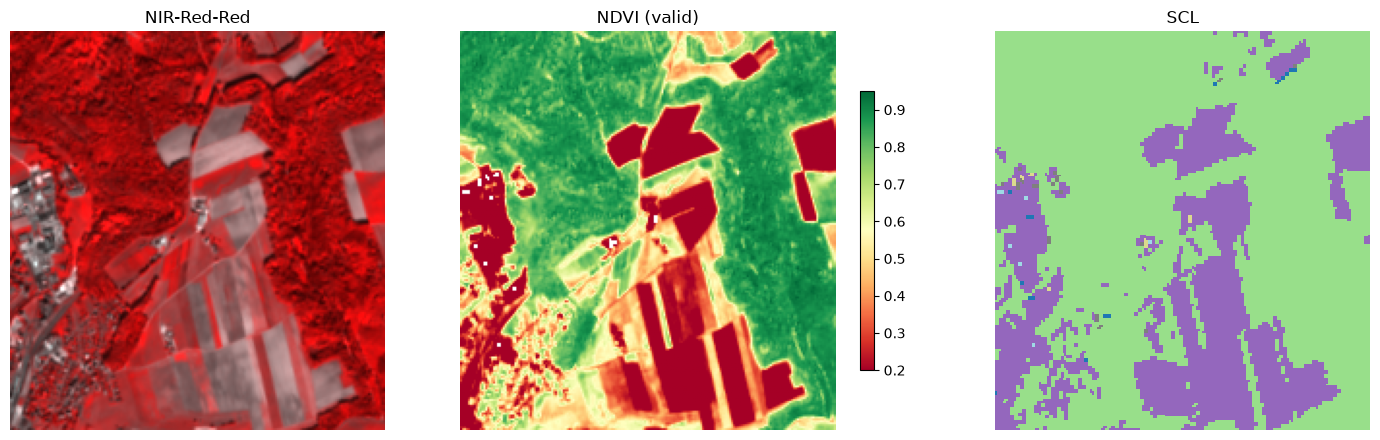

In [3]:
best = next(i for i in items if i.id == cc[0][2])
baseline = float(best.properties.get("s2:processing_baseline", "0"))
t0 = time.time()
ds = odc.stac.load([best], bands=["B04", "B08", "SCL"], bbox=TEST_BBOX, crs=CRS, resolution=RES,
                   resampling={"*": "bilinear", "SCL": "nearest"}).isel(time=0).compute()
off = 0.1 if baseline >= 4.0 else 0.0                       # +1000 DN offset since baseline 04.00
red = (ds.B04.where(ds.B04 > 0) * 1e-4 - off).clip(0, 1)
nir = (ds.B08.where(ds.B08 > 0) * 1e-4 - off).clip(0, 1)
ndvi = (nir - red) / (nir + red)
valid = ~ds.SCL.isin([0, 1, 3, 8, 9, 10, 11])
result.update(item=best.id, baseline=baseline, load_seconds=round(time.time() - t0, 1),
              pixels=int(ds.SCL.size), valid_share=round(float(valid.mean()), 3),
              ndvi_median=round(float(ndvi.where(valid).median()), 3))
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].imshow(np.dstack([nir, red, red]).clip(0, 0.4) / 0.4); ax[0].set_title("NIR-Red-Red")
im = ax[1].imshow(ndvi.where(valid), cmap="RdYlGn", vmin=0.2, vmax=0.95); plt.colorbar(im, ax=ax[1], shrink=.7); ax[1].set_title("NDVI (valid)")
ax[2].imshow(ds.SCL, cmap="tab20", interpolation="nearest"); ax[2].set_title("SCL")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 3 · Time coverage check (search only)
Number of scenes per year and window for the full AOI, to see whether the 2017–2026 comparison is feasible.

In [5]:
rows = []
for y in range(2017, 2027):
    for w, (a, b) in {"peak": ("06-15", "07-31"), "late": ("08-15", "09-30")}.items():
        its = list(cat.search(collections=["sentinel-2-l2a"], bbox=AOI_BBOX, datetime=f"{y}-{a}/{y}-{b}",
                              query={"eo:cloud_cover": {"lt": 70}}).item_collection())
        rows.append(dict(year=y, window=w, n_items=len(its),
                         min_cloud=min((i.properties["eo:cloud_cover"] for i in its), default=np.nan)))
cov = pd.DataFrame(rows)
cov.pivot(index="window", columns="year", values="n_items")

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
window,,,,,,,,,,
late,11,16,15,10,11,24,19,10,23,16
peak,11,17,18,17,9,22,16,8,20,22


## 4 · Label / vector data check

In [7]:
label_file = DATA / "labels" / f"{AOI}_labels.gpkg"
result["labels_available"] = label_file.exists()
print("labels found:" if label_file.exists() else "no label file yet:", label_file)

no label file yet: /Users/davidleu/Desktop/sds320-project/data/labels/ajoie_ju_labels.gpkg


## 5 · Record the test result

In [8]:
pd.DataFrame([result]).to_csv(DATA / "data_test_results.csv", index=False)
cov.to_csv(DATA / "scene_coverage_by_year.csv", index=False)
print(json.dumps(result, indent=2))

{
  "aoi": "ajoie_ju",
  "window": "2018-08-15/2018-09-30",
  "n_scenes": 16,
  "search_seconds": 22.7,
  "best_cloud": 0.038878,
  "item": "S2B_MSIL2A_20180927T103019_R108_T31TGN_20201009T053640",
  "baseline": 2.12,
  "load_seconds": 27.0,
  "pixels": 39964,
  "valid_share": 0.998,
  "ndvi_median": 0.719,
  "labels_available": false
}


**Interpretation**
- *What worked:* the STAC search (16 scenes for late summer 2018, best scene 0.04 % cloud), loading a 2 × 2 km subset, the SCL cloud mask (99.8 % valid pixels) and NDVI (median 0.72, plausible for a forest/farmland mix). Every year from 2017 to 2026 has at least 8 scenes per window.
- *What did not work:* no label file exists. The HETRES ground truth is not public (the STDL repository holds code only; the data belong to the Canton of Jura). Loading the full AOI through `odc-stac` + dask later hung, because the Ajoie straddles two MGRS tiles in different UTM zones. Notebook 02 therefore reads the scenes with plain `rasterio`.
- *Next decision:* work with a decline proxy from Sentinel-2 until labels are available, and state this in every result (notebooks 06–08).
